Successfully read the data!


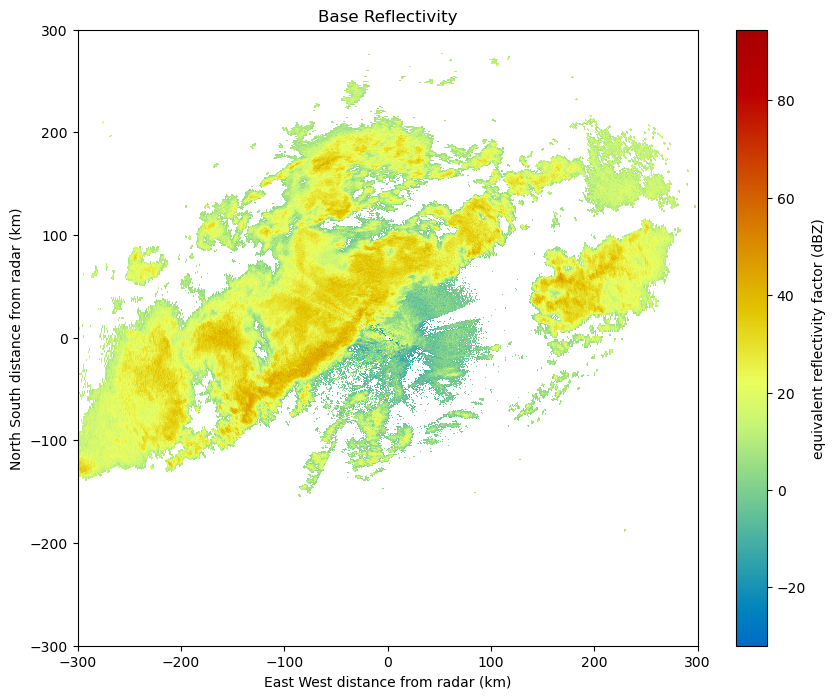

In [7]:
import pyart
import matplotlib.pyplot as plt
from cartopy import crs as ccrs
from cartopy.feature import BORDERS, COASTLINE

# 嘗試讀取資料
try:
    radar = pyart.io.read_nexrad_archive("c:\\Users\\victo\\Downloads\\Radar_data\\Radar_data\\20220326_1541_RCWF_VOL.082")
    print("Successfully read the data!")
except Exception as e:
    print("Failed to read the data:", e)
    radar = None

# 如果成功讀取，嘗試畫出基本反射率圖
if radar:
    display = pyart.graph.RadarDisplay(radar)
    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111)
    display.plot('reflectivity', 0, ax=ax, title="Base Reflectivity")
    display.set_limits((-300, 300), (-300, 300), ax=ax)
    plt.show()


Printing: reflectivity
Printing: differential_reflectivity
Printing: differential_phase
Printing: cross_correlation_ratio
Printing: velocity
Printing: spectrum_width


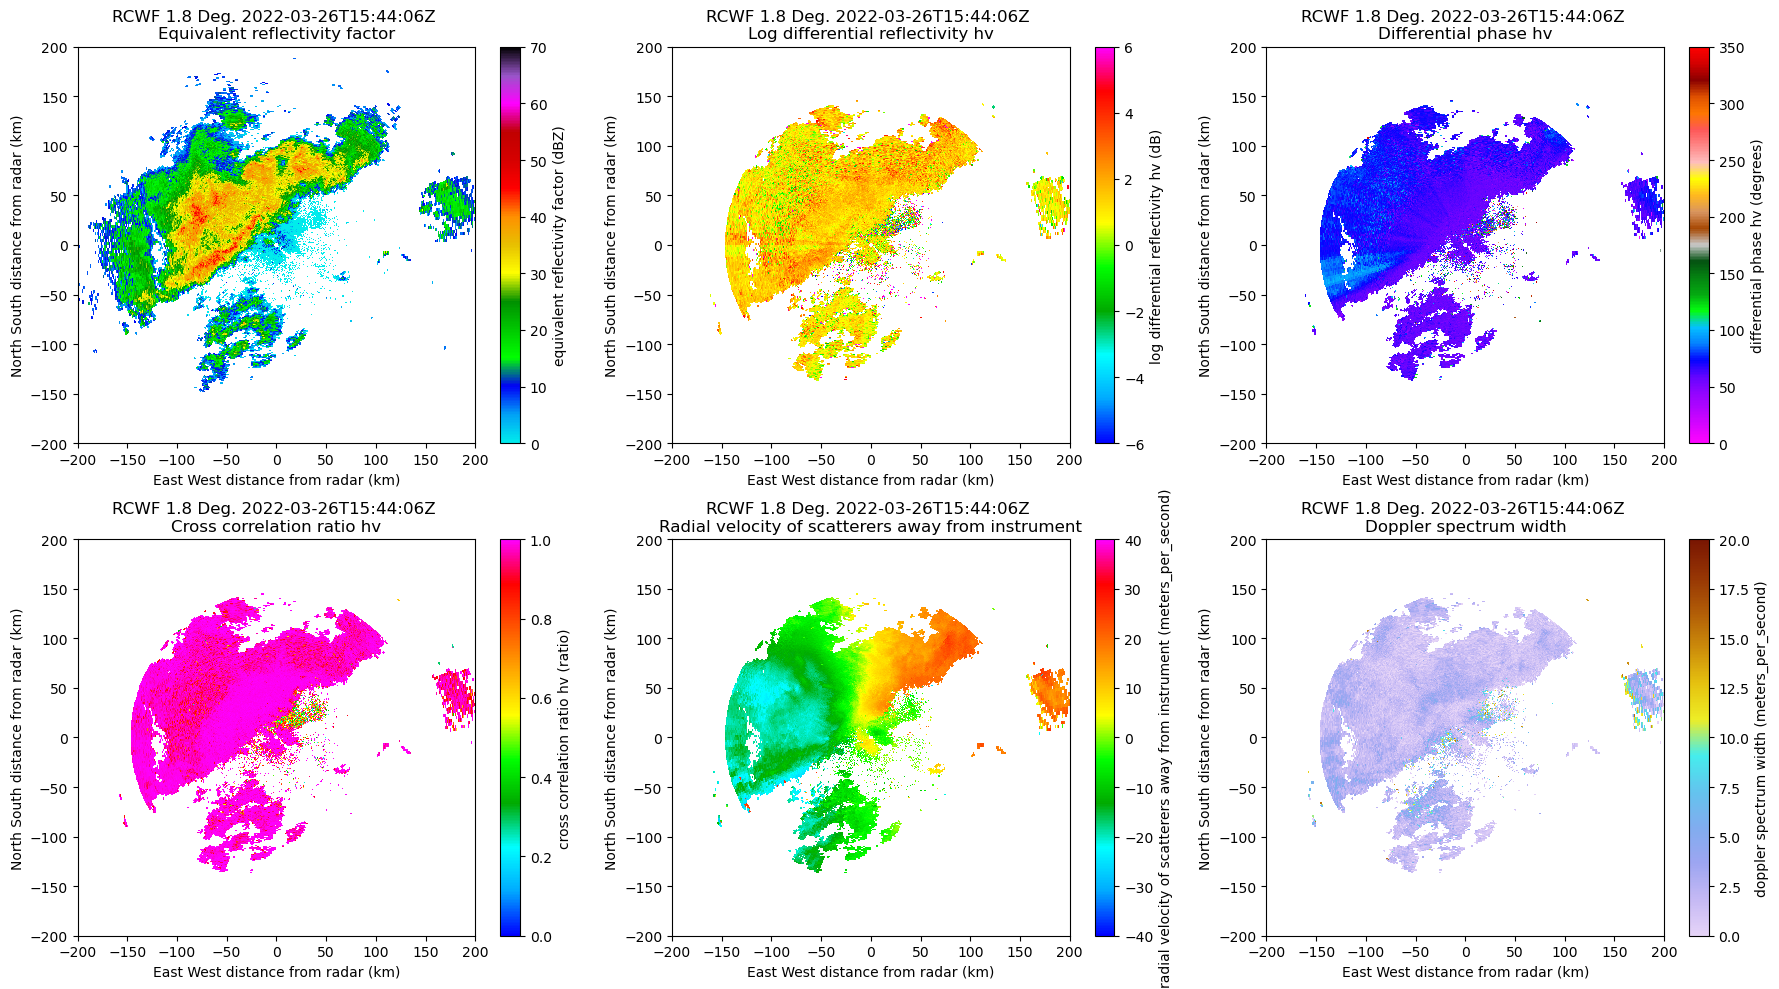

In [45]:
from __future__ import print_function
import matplotlib.pyplot as plt
from cartopy import crs as ccrs
from cartopy.feature import COASTLINE, BORDERS
import pyart
import numpy as np

radar = pyart.io.read_nexrad_archive("c:\\Users\\victo\\Downloads\\Radar_data\\Radar_data\\20220326_1541_RCWF_VOL.082")
nyquist = radar.instrument_parameters['nyquist_velocity']['data'][0]

fields_to_plot = {
    'reflectivity': ('NWSRef', 0, 70),
    'differential_reflectivity': ('RefDiff', -6, 6),
    'differential_phase': ('Wild25', 0, 350),
    'cross_correlation_ratio': ('RefDiff', 0, 1),
    'velocity': ('RefDiff', -40, 40),
    'spectrum_width': ('LangRainbow12', 0, 20),
}

# 創建圖表，設置子圖布局
fig, axes = plt.subplots(2, 3, figsize=(18, 10))  # 2 行 3 列的布局
axes = axes.ravel()  

# 繪製每個場
for i, (field, (cmap, vmin, vmax)) in enumerate(fields_to_plot.items()):
    print(f"Printing: {field}")
    display = pyart.graph.RadarMapDisplay(radar)
    display.plot_ppi(
        field,
        sweep=6,  # 指定掃描角
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
        ax=axes[i]  # 指定當前子圖
    )
    axes[i].set_ylim([-200,200])
    axes[i].set_xlim([-200,200])

# 顯示整體圖表
plt.tight_layout()
plt.savefig('c:\\Users\\victo\\Downloads\\hw3-1.png',dpi=300)
plt.show()


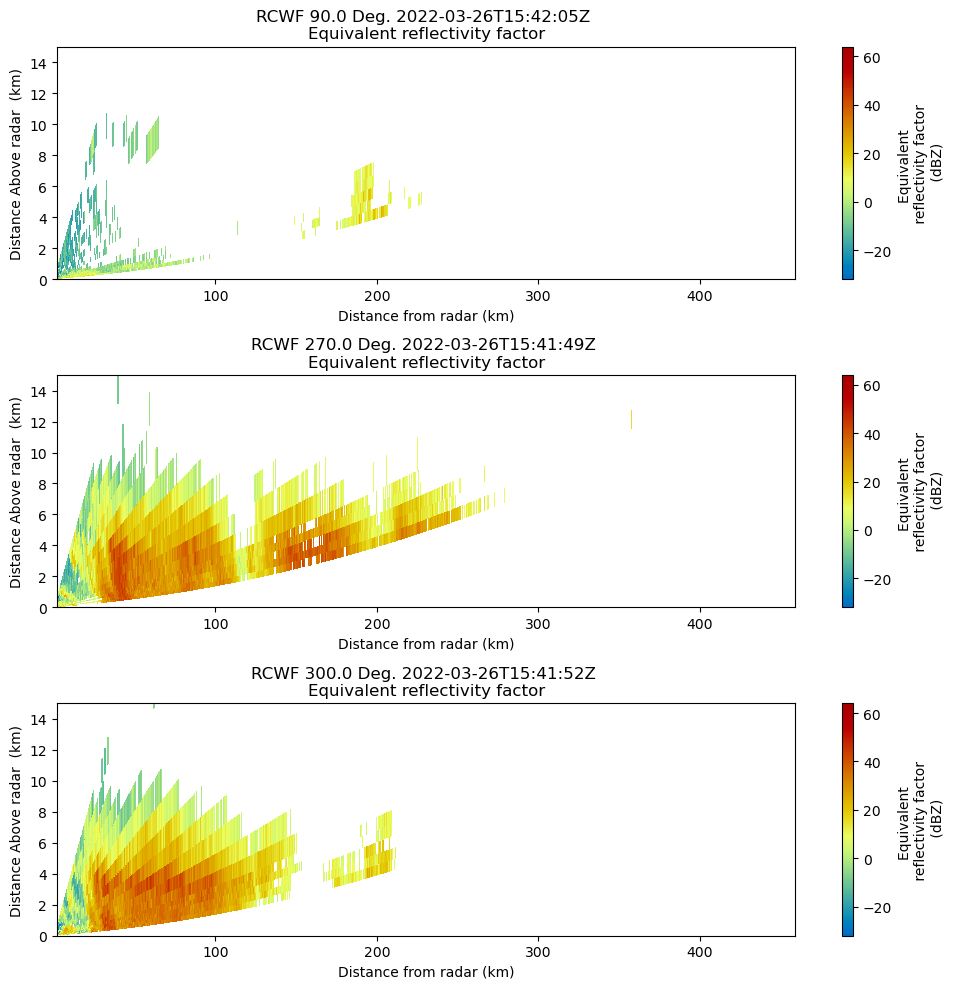

In [ ]:
from __future__ import print_function
import matplotlib.pyplot as plt
from cartopy import crs as ccrs
from cartopy.feature import COASTLINE, BORDERS
import pyart

# 讀取雷達數據
radar = pyart.io.read_nexrad_archive("c:\\Users\\victo\\Downloads\\Radar_data\\Radar_data\\20220326_1541_RCWF_VOL.082")
xsect = pyart.util.cross_section_ppi(radar, [90, 270, 300])

# Set the colorbar label
colorbar_label = "Equivalent \n reflectivity factor \n (dBZ)"

display = pyart.graph.RadarDisplay(xsect)
fig = plt.figure(figsize=(10, 10))
ax1 = fig.add_subplot(311)
display.plot(
    "reflectivity", 0, vmin=-32, vmax=64.0, colorbar_label=colorbar_label
)
plt.ylim(0, 15)
ax2 = fig.add_subplot(312)
display.plot(
    "reflectivity", 1, vmin=-32, vmax=64.0, colorbar_label=colorbar_label
)
plt.ylim(0, 15)
ax3 = fig.add_subplot(313)
display.plot(
    "reflectivity", 2, vmin=-32, vmax=64.0, colorbar_label=colorbar_label
)

plt.ylim(0, 15)
plt.tight_layout()
plt.savefig('c:\\Users\\victo\\Downloads\\hw3-2.png',dpi=300)
plt.show()

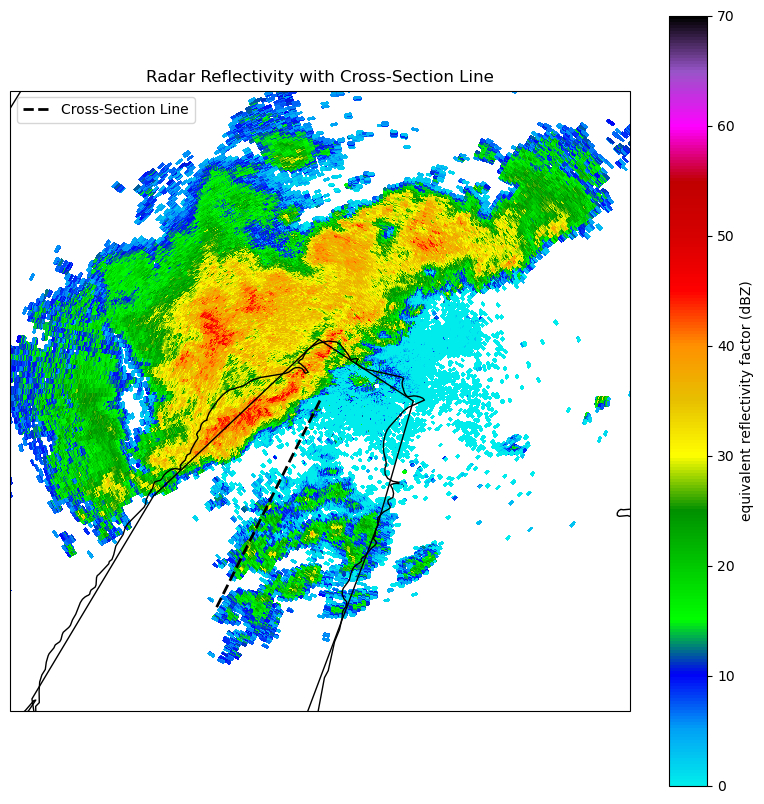

ValueError: The truth value of an array with more than one element is ambiguous. Use a.any() or a.all()

In [ ]:
import matplotlib.pyplot as plt
from cartopy import crs as ccrs
from cartopy.feature import COASTLINE, BORDERS
import pyart

# 讀取雷達數據
radar = pyart.io.read_nexrad_archive("c:\\Users\\victo\\Downloads\\Radar_data\\Radar_data\\20220326_1541_RCWF_VOL.082")

# 設定參數
field_to_plot = "reflectivity"
sweep = 6  
vmin, vmax = 0, 70  
cmap = "NWSRef"  

# 定義 cross-section 的端點
start_point = (24.0, 121.0)  
end_point = (25.0, 121.5)  

# 創建圖表
fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(1, 1, 1, projection=ccrs.PlateCarree())

# 繪製雷達圖
display = pyart.graph.RadarMapDisplay(radar)
display.plot_ppi_map(
    field_to_plot, sweep=sweep, cmap=cmap, vmin=vmin, vmax=vmax,
    min_lon=120.5, max_lon=122.5, min_lat=23.5, max_lat=25.5,
    ax=ax, title="Radar Reflectivity with Cross-Section Line"
)

# 添加海岸線和國界
ax.add_feature(COASTLINE, linewidth=1, edgecolor="black")

# 繪製 cross-section 線
ax.plot(
    [start_point[1], end_point[1]],  # 經度
    [start_point[0], end_point[0]],  # 緯度
    color="black", linewidth=2, linestyle="--", label="Cross-Section Line"
)

# 添加圖例
ax.legend(loc="upper left")

# 調整顯示範圍
ax.set_extent([120, 123, 23.5, 26.5], crs=ccrs.PlateCarree())

# 顯示圖表
plt.show()

# 提取 cross-section 數據
cross_section_data = pyart.util.cross_section_ppi(radar, start_point, end_point)

# 繪製 cross-section
fig, ax = plt.subplots(figsize=(10, 6))
field = cross_section_data.fields[field_to_plot]["data"]
x = cross_section_data.range["data"] / 1000.0  # 將範圍轉換為公里
z = cross_section_data.gate_altitude["data"] / 1000.0  # 將高度轉換為公里
mesh = ax.pcolormesh(
    x, z, field.T, cmap=cmap, vmin=vmin, vmax=vmax, shading="auto"
)
plt.colorbar(mesh, ax=ax, label="Reflectivity (dBZ)")
ax.set_xlabel("Distance from radar (km)")
ax.set_ylabel("Altitude (km)")
ax.set_title("Cross-Section of Reflectivity")
plt.show()
